# 01 · Data pipeline: BTC/USDT 1-second klines since January 2023

**Task:** *"Using python and publicly available APIs, retrieve BTC/USDT pair 1-second kline data since January 2023."*

This notebook does four things, in order:

1. **Download** every month from Binance's public archive, and verify each file against Binance's own SHA-256 checksum.
2. **Store** each month as a Parquet file, unchanged.
3. **Audit** the data: missing seconds, duplicates, out-of-order rows, impossible bars.
4. **Clean** it with three documented rules, and build 1-minute bars for the later notebooks.

All logic lives in `src/btc/`; the notebook only calls it and shows the results.

### Why two data sources

| Source | Used for | Why |
|---|---|---|
| Bulk archive `data.binance.vision` | Every complete month | One zip per month with a checksum. The same history through the REST API would take about 120,000 requests of 1,000 rows each. |
| Daily archive files, same site | The days after the last monthly file | The archive publishes a month only after it ends, but publishes each day shortly after it ends, also with a checksum. |
| REST API `/api/v3/klines` | Only days whose daily file is not out yet | About 87 requests per day, so far slower than the archive. |

Both are public and need no API key. Binance is used because it is the largest BTC/USDT spot venue and one of the few that publishes 1-second klines.

### What one row contains

| Column | Meaning |
|---|---|
| `open`, `high`, `low`, `close` | First, highest, lowest and last traded price in that second |
| `volume` | BTC traded |
| `quote_volume` | USDT traded |
| `trades` | Number of trades |
| `taker_buy_volume` | BTC bought by aggressive buyers (market orders lifting the offer). `volume − taker_buy_volume` is aggressive selling. |

## Settings

In [1]:
SYMBOL, INTERVAL = "BTCUSDT", "1s"
START = "2023-01"
END = "2026-10"        # last complete month of the analysis snapshot (None = the last complete calendar month)
FETCH_TAIL = False     # True = also fetch the days after END (daily archive files, REST API as fallback)
# The analysis snapshot ends 2026-11-14 23:59:59 UTC: the 1-14 Nov 2026 daily files were fetched on 2026-11-15
# and are already on disk. Keeping FETCH_TAIL = False freezes the data used by notebooks 02-05.
WORKERS = 4            # parallel downloads
DATA_DIR = None        # None = <repo>/data

In [2]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from btc import data, quality, patterns, plotting
plotting.use_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

DATA = Path(DATA_DIR) if DATA_DIR else ROOT / "data"
RAW, PQ, PROC = DATA / "raw", DATA / "parquet", DATA / "processed"
for d in (RAW, PQ, PROC): d.mkdir(parents=True, exist_ok=True)

## 1. Download and verify

`fetch_month` is **idempotent**: a file already on disk that matches its checksum is skipped, so the cell can be re-run after an interruption and only fetches what is missing. Failed requests are retried with exponential backoff; a file whose checksum does not match is downloaded once more and then flagged.

In [3]:
end = END or data.last_complete_month()
log = data.fetch_all(START, end, RAW, workers=WORKERS, symbol=SYMBOL, interval=INTERVAL)
print(f"{len(log)} months requested, {int(log.sha256_ok.sum())} verified, {log.mb.sum()/1e3:.2f} GB of zips")
log

46 months requested, 46 verified, 3.63 GB of zips


,file,status,mb,sha256_ok
month,,,,
2023-01,BTCUSDT-1s-2023-01.zip,cached,114.2011,True
2023-02,BTCUSDT-1s-2023-02.zip,cached,105.1581,True
2023-03,BTCUSDT-1s-2023-03.zip,cached,107.8652,True
2023-04,BTCUSDT-1s-2023-04.zip,cached,78.9138,True
2023-05,BTCUSDT-1s-2023-05.zip,cached,76.7293,True
2023-06,BTCUSDT-1s-2023-06.zip,cached,73.1346,True
2023-07,BTCUSDT-1s-2023-07.zip,cached,69.2187,True
2023-08,BTCUSDT-1s-2023-08.zip,cached,68.4452,True
2023-09,BTCUSDT-1s-2023-09.zip,cached,67.5878,True


In [4]:
bad = log[~log.sha256_ok]
if len(bad):
    print("NOT verified, excluded from everything below:"); display(bad)
else:
    print("Every file matches its SHA-256 checksum.")

Every file matches its SHA-256 checksum.


## 2. Store as Parquet

Each verified zip is converted to one Parquet file, **exactly as published** (no sorting, no de-duplication), so the audit in step 3 sees what Binance actually shipped.

One trap handled in `data.to_utc`: the archive's timestamps are in **milliseconds** in older files and **microseconds** in newer ones. Reading a microsecond file as milliseconds puts the data tens of thousands of years in the future. The parser detects the unit from the size of the number.

Parquet is used because it is columnar and compressed: later notebooks can read one column of one month without touching the rest.

In [5]:
for m in log.index[log.sha256_ok]:
    data.zip_to_parquet(RAW / f"{SYMBOL}-{INTERVAL}-{m}.zip", PQ)

files = data.parquet_files(PQ, SYMBOL, INTERVAL)
print(f"{len(files)} parquet files, {sum(f.stat().st_size for f in files)/1e9:.2f} GB")

47 parquet files, 3.44 GB


### The days after the last monthly file

The monthly archive stops at the last complete month. The days after it, up to the end of yesterday (UTC), come from Binance's **daily** archive files: one zip per day, verified against its own SHA-256 checksum like the monthly ones and skipped on a re-run once on disk.

A day whose file is not published yet (usually just yesterday) falls back to the REST API, in pages of 1,000 seconds.

These days are written to a parquet file for the current month, which is rebuilt each time this cell runs. When that month's full zip comes out, step 2 replaces the file with it.

In [6]:
if FETCH_TAIL:
    first = (pd.Period(end, freq="M") + 1).start_time
    yesterday = pd.Timestamp.now(tz="UTC").tz_localize(None).floor("D") - pd.Timedelta(days=1)
    if yesterday >= first:
        DAILY = RAW / "daily"
        dlog = data.fetch_days(first, yesterday, DAILY, workers=WORKERS, symbol=SYMBOL, interval=INTERVAL)
        parts = []
        for day, ok in dlog.sha256_ok.items():
            if ok:
                parts.append(data.read_zip(DAILY / f"{SYMBOL}-{INTERVAL}-{day}.zip"))
            else:  # not published yet: REST API for that one day
                t0 = pd.Timestamp(day, tz="UTC")
                parts.append(data.fetch_api(t0, t0 + pd.Timedelta(days=1), SYMBOL, INTERVAL))
                dlog.loc[day, "status"] += " -> REST API"
        tail = pd.concat(parts)
        for m, part in tail.groupby(tail.index.strftime("%Y-%m")):
            part.to_parquet(PQ / f"{SYMBOL}-{INTERVAL}-{m}.parquet", compression="zstd")
        print(f"Tail: {len(dlog)} days, {int(dlog.sha256_ok.sum())} from verified daily files, "
              f"{len(tail):,} rows up to {tail.index.max()}")
        bad_days = dlog[~dlog.sha256_ok]
        if len(bad_days): display(bad_days)
        else: print("Every daily file matches its SHA-256 checksum.")
    files = data.parquet_files(PQ, SYMBOL, INTERVAL)
else:
    print("FETCH_TAIL is off: no new days are fetched; the parquet files already on disk are used as they are.")

FETCH_TAIL is off: no new days are fetched; the parquet files already on disk are used as they are.


## 3. Data-quality audit

Every month is checked on the raw data, before any cleaning. For a complete month, the expected row count is simply the number of seconds in that month.

| Check | What it catches |
|---|---|
| `missing_seconds`, `coverage_pct` | Seconds with no row at all |
| `duplicate_rows` | The same timestamp more than once |
| `out_of_order_rows` | A row earlier than the row before it |
| `outside_month_rows` | Rows that belong to a different month than the file name says |
| `null_values`, `nonpositive_prices` | Corrupt fields |
| `ohlc_inconsistent` | Impossible bars: high below open or close, low above them |
| `taker_gt_total` | Taker-buy volume larger than total volume |
| `zero_volume_pct` | Seconds in which nothing traded |
| `n_gaps`, `longest_gap_s` | How the missing seconds are grouped |

In [7]:
this_month = str(pd.Timestamp.now(tz="UTC").tz_localize(None).to_period("M"))
rows, gaps = [], []
for f in files:
    month = f.stem[-7:]
    df = pd.read_parquet(f)
    rows.append(quality.check_month(df, month, partial=(month == this_month)))
    gaps.append(quality.find_gaps(df, None if month == this_month else month))

report = pd.DataFrame(rows).set_index("month")
gaps = pd.concat(gaps, ignore_index=True)
report.to_csv(PROC / "quality_report.csv"); gaps.to_csv(PROC / "gaps.csv", index=False)

tot = report.sum(numeric_only=True)
print(f"Rows:             {int(tot.rows):,}")
print(f"Expected seconds: {int(tot.expected_seconds):,}")
print(f"Missing seconds:  {int(tot.missing_seconds):,}  ({100*tot.missing_seconds/tot.expected_seconds:.4f}%)")
print(f"Duplicate rows:   {int(tot.duplicate_rows):,}")
print(f"Bad rows (null / non-positive / inconsistent OHLC): "
      f"{int(tot.null_values + tot.nonpositive_prices + tot.ohlc_inconsistent):,}")
report.style.format({"coverage_pct": "{:.4f}", "zero_volume_pct": "{:.2f}"}, thousands=",")

Rows:             122,160,829
Expected seconds: 122,169,600
Missing seconds:  8,771  (0.0072%)
Duplicate rows:   0
Bad rows (null / non-positive / inconsistent OHLC): 0


,rows,expected_seconds,missing_seconds,coverage_pct,duplicate_rows,out_of_order_rows,outside_month_rows,null_values,nonpositive_prices,ohlc_inconsistent,taker_gt_total,zero_volume_pct,n_gaps,longest_gap_s
month,,,,,,,,,,,,,,
2023-01,"2,676,454","2,678,400","1,946",99.9273,0,0,0,0,0,0,0,0.09,"1,946",1
2023-02,"2,418,466","2,419,200",734,99.9697,0,0,0,0,0,0,0,0.09,734,1
2023-03,"2,672,309","2,678,400","6,091",99.7726,0,0,0,0,0,0,0,1.45,"1,274","4,818"
2023-04,"2,592,000","2,592,000",0,100.0000,0,0,0,0,0,0,0,4.71,0,0
2023-05,"2,678,400","2,678,400",0,100.0000,0,0,0,0,0,0,0,7.78,0,0
2023-06,"2,592,000","2,592,000",0,100.0000,0,0,0,0,0,0,0,8.55,0,0
2023-07,"2,678,400","2,678,400",0,100.0000,0,0,0,0,0,0,0,12.13,0,0
2023-08,"2,678,400","2,678,400",0,100.0000,0,0,0,0,0,0,0,13.20,0,0
2023-09,"2,592,000","2,592,000",0,100.0000,0,0,0,0,0,0,0,11.70,0,0


### Where the missing seconds are

A month with full coverage has no bar. The table lists the longest individual gaps; long ones usually line up with exchange maintenance or outages, and are worth checking against Binance's announcements before presenting.

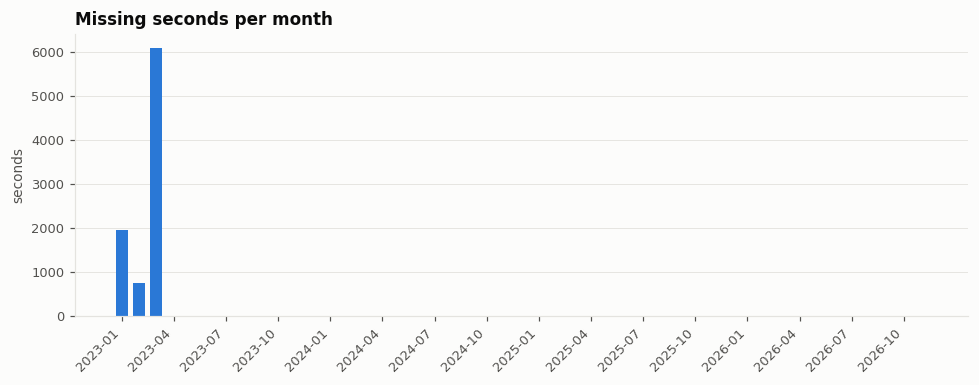

3954 gaps in total. Longest 15:


,first_missing,last_missing,missing_seconds
0,2023-03-24 12:39:42+00:00,2023-03-24 13:59:59+00:00,4818
1,2023-01-01 01:06:39+00:00,2023-01-01 01:06:39+00:00,1
2,2023-01-01 03:05:25+00:00,2023-01-01 03:05:25+00:00,1
3,2023-01-01 03:22:05+00:00,2023-01-01 03:22:05+00:00,1
4,2023-01-01 03:38:45+00:00,2023-01-01 03:38:45+00:00,1
5,2023-01-01 04:11:19+00:00,2023-01-01 04:11:19+00:00,1
6,2023-01-01 04:27:59+00:00,2023-01-01 04:27:59+00:00,1
7,2023-01-01 04:44:39+00:00,2023-01-01 04:44:39+00:00,1
8,2023-01-01 05:10:26+00:00,2023-01-01 05:10:26+00:00,1
9,2023-01-01 05:27:06+00:00,2023-01-01 05:27:06+00:00,1


In [8]:
fig, ax = plt.subplots()
ax.bar(report.index, report.missing_seconds, width=0.7, color=plotting.BLUE)
ax.set_title("Missing seconds per month"); ax.set_ylabel("seconds")
k = max(1, len(report) // 12)
ax.set_xticks(range(0, len(report), k)); ax.set_xticklabels(report.index[::k], rotation=45, ha="right")
plt.tight_layout(); plt.show()

print(f"{len(gaps)} gaps in total. Longest 15:")
gaps.sort_values("missing_seconds", ascending=False).head(15).reset_index(drop=True)

## 4. Clean, and build 1-minute bars

`data.clean` makes exactly three edits:

1. sort by time;
2. where a timestamp appears more than once, keep the last row;
3. drop rows with a non-positive price or `high < low`.

**Missing seconds are not filled.** Inventing prices for seconds that have no data would create returns that never happened. Instead, each 1-minute bar records `n_obs`, the number of seconds it was built from, so later notebooks can exclude thin bars.

The 1-second files stay as they are; cleaning is applied when they are read. The 1-minute bars are saved as one file for the modelling notebooks.

In [9]:
bars, removed = [], 0
for f in files:
    raw = pd.read_parquet(f)
    cl = data.clean(raw)
    removed += len(raw) - len(cl)
    bars.append(data.resample_bars(cl, "1min"))

m1 = pd.concat(bars)
m1 = m1[~m1.index.duplicated(keep="last")].sort_index()
m1.to_parquet(PROC / f"{SYMBOL}-1m.parquet", compression="zstd")

print(f"Rows removed by cleaning: {removed:,}")
print(f"1-minute bars: {len(m1):,} from {m1.index.min()} to {m1.index.max()}")
print(f"Bars built from all 60 seconds: {100*(m1.n_obs == 60).mean():.3f}%")
m1.tail(3)

Rows removed by cleaning: 0
1-minute bars: 2,036,080 from 2023-01-01 00:00:00+00:00 to 2026-11-14 23:59:00+00:00
Bars built from all 60 seconds: 99.806%


,open,high,low,close,volume,quote_volume,trades,taker_buy_volume,n_obs
time,,,,,,,,,
2026-11-14 23:57:00+00:00,"64,104.0100","64,199.9700","64,104.0100","64,199.9600",17.6432,"1,132,443.8187",2672,6.8508,60
2026-11-14 23:58:00+00:00,"64,199.9700","64,199.9700","64,160.0000","64,178.0100",9.6451,"618,990.5300",2745,4.7014,60
2026-11-14 23:59:00+00:00,"64,178.0000","64,180.0100","64,146.0000","64,150.0000",9.5847,"614,952.9227",2314,4.3029,60


## Summary

- **Months downloaded and verified:** 46 of 46 monthly files (Jan 2023 – Oct 2026), plus 14 daily files for 1–14 Nov 2026. Every file matches its SHA-256 checksum.
- **Total rows and coverage:** 122,160,829 rows out of 122,169,600 expected seconds: 8,771 missing, **99.993% coverage**. No duplicates, out-of-order rows, nulls, non-positive prices, impossible bars or taker volume above total volume.
- **Longest gaps and their likely cause:**
  - **24 Mar 2023, 12:39:42 – 13:59:59 UTC (4,818 s):** the only long gap. It matches Binance's spot trading halt that afternoon.
  - **3,953 single missing seconds, all in Jan–Mar 2023:** most are exactly 1,000 s apart. That regular spacing points to how the early archive files were generated, not to real market outages. From April 2023 onwards every month is 100% complete.
- **Rows removed by cleaning:** 0. The data needed no edits; the cleaning rules are kept as a safeguard. The 1-minute file has 2,036,080 bars, built from all 122,160,829 seconds.


**Outputs**

| File | Contents |
|---|---|
| `data/raw/*.zip` + `.CHECKSUM` | Files as downloaded |
| `data/parquet/BTCUSDT-1s-YYYY-MM.parquet` | 1-second klines, as published |
| `data/processed/quality_report.csv`, `gaps.csv` | The audit |
| `data/processed/BTCUSDT-1m.parquet` | Clean 1-minute bars |